<a href="https://colab.research.google.com/github/liangjingyi1211/neural-search-ranking/blob/main/notebooks/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from pathlib import Path
import os
import sys
import torch

PROJECT_DIR = Path("/content/neural-search-ranking")
REPO_URL = "https://github.com/liangjingyi1211/neural-search-ranking.git"

if not (PROJECT_DIR / ".git").exists():
    !git clone {REPO_URL}

os.chdir(PROJECT_DIR)

print("Project:", os.getcwd())
print("Python:", sys.version)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Cloning into 'neural-search-ranking'...
remote: Enumerating objects: 27, done.
remote: Counting objects: 100% (27/27), done.
remote: Compressing objects: 100% (23/23), done.
remote: Total 27 (delta 3), reused 20 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (27/27), 5.40 MiB | 10.71 MiB/s, done.
Resolving deltas: 100% (3/3), done.
Project: /content/neural-search-ranking
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
GPU: Tesla T4


In [ ]:
%pip install -q beir rank-bm25 pandas matplotlib

下载 FiQA

In [ ]:
from beir import util
from beir.datasets.data_loader import GenericDataLoader

dataset_name = "fiqa"

url = (
    "https://public.ukp.informatik.tu-darmstadt.de/"
    "thakur/BEIR/datasets/fiqa.zip"
)

data_path = util.download_and_unzip(
    url,
    str(PROJECT_DIR / "data")
)

print("Dataset location:", data_path)

/usr/local/lib/python3.13/dist-packages/beir/util.py:11: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


/content/neural-search-ranking/data/fiqa.zip:   0%|          | 0.00/17.1M [00:00<?, ?iB/s]

Dataset location: /content/neural-search-ranking/data/fiqa


加载不同的数据划分，每次加载不同 split，都新建一个 GenericDataLoader 对象

In [ ]:
from beir.datasets.data_loader import GenericDataLoader

# 加载 train
corpus, train_queries, train_qrels = GenericDataLoader(
    data_folder=data_path
).load(split="train")

# 加载 dev：使用新的 Loader
_, dev_queries, dev_qrels = GenericDataLoader(
    data_folder=data_path
).load(split="dev")

print("Documents:", len(corpus))
print("Train Queries:", len(train_queries))
print("Dev Queries:", len(dev_queries))

print("Train Qrels:", len(train_qrels))
print("Dev Qrels:", len(dev_qrels))

  0%|          | 0/57638 [00:00<?, ?it/s]

  0%|          | 0/57638 [00:00<?, ?it/s]

Documents: 57638
Train Queries: 5500
Dev Queries: 500
Train Qrels: 5500
Dev Qrels: 500


In [ ]:
# 检查 train 和 dev 的查询 ID
train_ids = set(train_queries)
dev_ids = set(dev_queries)

print("Train / Dev overlapping queries:", len(train_ids & dev_ids))

# 检查相关性标注是否能找到对应文档
print(
    "Missing document references:",
    sum(
        doc_id not in corpus
        for docs in dev_qrels.values()
        for doc_id in docs
    )
)

Train / Dev overlapping queries: 0
Missing document references: 0


查看真实的数据样本

In [ ]:
import pandas as pd

# 查看第一个 Dev Query
qid = next(iter(dev_queries))
query = dev_queries[qid]

print("Query ID:", qid)
print("Query:", query)

print("\nRelevant Documents:")

for doc_id, relevance in dev_qrels[qid].items():
    document = corpus[doc_id]

    print("\nDocument ID:", doc_id)
    print("Relevance:", relevance)
    print("Title:", document.get("title", ""))
    print("Text:", document.get("text", "")[:500])

Query ID: 1
Query: Claiming business expenses for a business with no income

Relevant Documents:

Document ID: 14255
Relevance: 1
Title: 
Text: Yes you can claim your business deductions if you are not making any income yet. But first you should decide what structure you want to have for your business. Either a Company structure or a Sole Trader or Partnership. Company Structure If you choose a Company Structure (which is more expensive to set up) you would claim your deductions but no income. So you would be making a loss, and continue making losses until your income from the business exceed your expenses. So these losses will remain i


分析文档长度

In [ ]:
texts = [
    (doc.get("title", "") + " " + doc.get("text", "")).strip()
    for doc in corpus.values()
]

word_lengths = [len(text.split()) for text in texts]

df = pd.DataFrame({
    "word_count": word_lengths
})

print(df.describe(
    percentiles=[0.5, 0.9, 0.95, 0.99]
))

         word_count
count  57638.000000
mean     132.904473
std      128.738342
min        0.000000
50%       90.000000
90%      270.000000
95%      368.000000
99%      641.630000
max     2973.000000


绘制文档长度分布

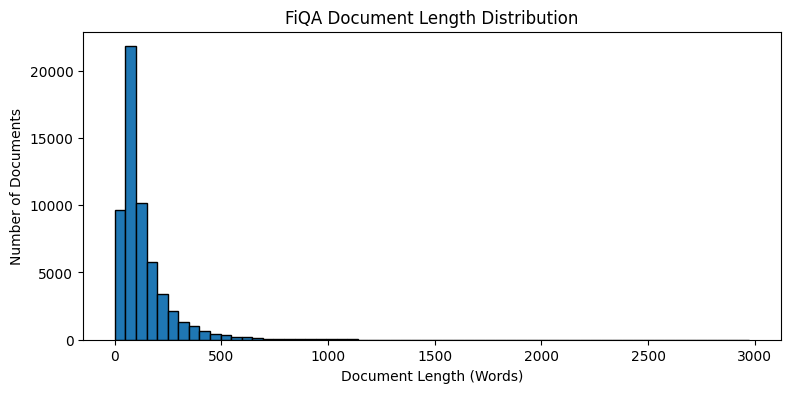

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))

plt.hist(
    word_lengths,
    bins=60,
    edgecolor="black"
)

plt.xlabel("Document Length (Words)")
plt.ylabel("Number of Documents")
plt.title("FiQA Document Length Distribution")

plt.show()

检查标注分布

In [ ]:
from collections import Counter

train_labels = Counter(
    int(score)
    for docs in train_qrels.values()
    for score in docs.values()
)

dev_labels = Counter(
    int(score)
    for docs in dev_qrels.values()
    for score in docs.values()
)

print("Train relevance distribution:", train_labels)
print("Dev relevance distribution:", dev_labels)

print(
    "Average relevant documents per dev query:",
    sum(
        sum(score > 0 for score in docs.values())
        for docs in dev_qrels.values()
    ) / len(dev_qrels)
)

Train relevance distribution: Counter({1: 14166})
Dev relevance distribution: Counter({1: 1238})
Average relevant documents per dev query: 2.476


建立BM25检索

In [ ]:
import re
import time
from rank_bm25 import BM25Okapi

def tokenize(text):
    return re.findall(r"[a-z0-9]+", text.lower())

doc_ids = list(corpus.keys())

doc_texts = [
    (
        corpus[doc_id].get("title", "") + " " +
        corpus[doc_id].get("text", "")
    ).strip()
    for doc_id in doc_ids
]

start = time.perf_counter()

tokenized_corpus = [
    tokenize(text)
    for text in doc_texts
]

bm25 = BM25Okapi(tokenized_corpus)

index_time = time.perf_counter() - start

print(f"Indexed documents: {len(doc_ids)}")
print(f"Index build time: {index_time:.2f}s")

Indexed documents: 57638
Index build time: 6.67s


运行一次检索

In [ ]:
import numpy as np

query_id = next(iter(dev_queries))
query_text = dev_queries[query_id]

scores = bm25.get_scores(tokenize(query_text))

top_indices = np.argsort(scores)[::-1][:5]

print("QUERY:", query_text)

for rank, idx in enumerate(top_indices, 1):
    print(f"\nRank {rank}")
    print("Score:", round(float(scores[idx]), 4))
    print("Document ID:", doc_ids[idx])
    print("Text:", doc_texts[idx][:300])

QUERY: Claiming business expenses for a business with no income

Rank 1
Score: 27.5977
Document ID: 541809
Text: "No, your business cannot deduct your non-business expenses.  You can only deduct from your business income those reasonable expenses you paid in order to earn income for the business. Moreover, for there to be a tax benefit, your business generally has to have income (but I expect there are excepti

Rank 2
Score: 26.9669
Document ID: 100764
Text: "You don't specify which country you are in, so my answers are more from a best practice view than a legal view.. I don't intend on using it for personal use, but I mean it's just as possible. This is a dangerous proposition.. You shouldn't co-mingle business expenses with personal expenses.  If the

Rank 3
Score: 26.7989
Document ID: 208989
Text: "It's not possible to determine whether you can ""expect a refund"" or whether you are claiming the right number of exemptions from the information given.   If your wife were not working 

对整个 Dev 集进行检索

In [ ]:
from tqdm.auto import tqdm

TOP_K = 100

bm25_results = {}
latencies_ms = []

for qid, query in tqdm(dev_queries.items()):
    start = time.perf_counter()

    scores = bm25.get_scores(tokenize(query))

    k = min(TOP_K, len(scores))

    top_idx = np.argpartition(
        scores, -k
    )[-k:]

    top_idx = top_idx[
        np.argsort(scores[top_idx])[::-1]
    ]

    bm25_results[qid] = {
        doc_ids[i]: float(scores[i])
        for i in top_idx
    }

    latency = (time.perf_counter() - start) * 1000
    latencies_ms.append(latency)

print("Evaluated queries:", len(bm25_results))

  0%|          | 0/500 [00:00<?, ?it/s]

Evaluated queries: 500


计算正式检索指标

In [ ]:
from beir.retrieval.evaluation import EvaluateRetrieval

k_values = [10, 100]

ndcg, _map, recall, precision = EvaluateRetrieval.evaluate(
    dev_qrels,
    bm25_results,
    k_values=k_values
)

mrr = EvaluateRetrieval.evaluate_custom(
    dev_qrels,
    bm25_results,
    k_values=[10],
    metric="mrr"
)

print("nDCG@10:", ndcg["NDCG@10"])
print("Recall@10:", recall["Recall@10"])
print("Recall@100:", recall["Recall@100"])
print("MRR@10:", mrr["MRR@10"])

nDCG@10: 0.22877
Recall@10: 0.27244
Recall@100: 0.47021
MRR@10: 0.28737


记录实验结果

In [ ]:
import json

report = {
    "dataset": "fiqa",
    "split": "dev",
    "method": "BM25Okapi",
    "tokenizer": "regex_lowercase_alphanumeric",
    "top_k": TOP_K,
    "ndcg_10": ndcg["NDCG@10"],
    "recall_10": recall["Recall@10"],
    "recall_100": recall["Recall@100"],
    "mrr_10": mrr["MRR@10"],
    "index_build_seconds": index_time,
    "p50_latency_ms": float(np.percentile(latencies_ms, 50)),
    "p95_latency_ms": float(np.percentile(latencies_ms, 95))
}

report_path = PROJECT_DIR / "reports" / "fiqa_bm25_dev.json"
report_path.parent.mkdir(parents=True, exist_ok=True)

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print(json.dumps(report, indent=2))

top100完全没有召回已标注相关文档的query

In [ ]:
failed_queries = []

for qid, query in dev_queries.items():
    relevant_docs = {
        doc_id
        for doc_id, score in dev_qrels[qid].items()
        if score > 0
    }

    retrieved_docs = set(bm25_results[qid].keys())

    if relevant_docs and not (relevant_docs & retrieved_docs):
        failed_queries.append(qid)

print("Total dev queries:", len(dev_queries))
print("Failed queries:", len(failed_queries))
print("Failure rate:", len(failed_queries) / len(dev_queries))

for qid in failed_queries[:3]:
    print("\nQuery:", dev_queries[qid])
    print("Relevant documents:")

    for doc_id, score in dev_qrels[qid].items():
        if score > 0:
            print(corpus[doc_id]["text"][:300])

Total dev queries: 500
Failed queries: 172
Failure rate: 0.344

Query: Transferring money from One business checking to another business checking
Relevant documents:
"You should have separate files for each of the two businesses.  The business that transfers money out should ""write check"" in its QB file.  The business that receives money should ""make deposit"" in its QB file. (In QB you ""write check"" even when you make the payment by some other means like A

Query: Income tax exemptions for small business?
Relevant documents:
Yes, you should be able to deduct at least some of these expenses.  For expense incurred before you started the business: What Are Deductible Startup Costs? The IRS defines “startup costs” as deductible capital expenses that are used to pay for: 1) The cost of “investigating the creation or acquisit

Query: Borrow money to invest in a business venture with equity?
Relevant documents:
It's clearly a risk, but is it any different than investing in your own busi